# Mini-projet Machine Learning — TweetEval : Hate Speech

**Classe :** CI1  
**Membres du groupe :** À compléter  
**Dataset :** TweetEval – Hate Speech  
**Cible :** `0 = Not-hate` ; `1 = Hate`

Ce notebook suit les étapes du descriptif du mini-projet : exploration et analyse des données, prétraitement, vectorisation TF-IDF, comparaison d'au moins cinq algorithmes, évaluation et sauvegarde du meilleur modèle.

**Important :** le nettoyage est recalculé exclusivement à partir de la colonne brute `text`. La colonne `text_clean` des anciens CSV n'est jamais réutilisée.

**Choix de nettoyage de cette version :** les URLs, les mentions (`@user`) et les hashtags (symbole `#` + mot du hashtag) sont supprimés entièrement ; les négations sont conservées ; la lemmatisation est désactivée car elle est facultative.


## 1. Importation des bibliothèques

In [1]:
import re
import html
import zipfile
import subprocess
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS, TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import MultinomialNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.base import clone
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay
)
import joblib

try:
    from wordcloud import WordCloud, STOPWORDS
except ImportError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "wordcloud"])
    from wordcloud import WordCloud, STOPWORDS

sns.set_theme(style="whitegrid")
pd.set_option("display.max_colwidth", 140)
LABEL_NAMES = {0: "Not-hate", 1: "Hate"}
RANDOM_STATE = 42
print("Bibliothèques importées.")

Bibliothèques importées.


## 2. Chargement des données avec Pandas

Le notebook privilégie les fichiers officiels TweetEval `train_text.txt`, `train_labels.txt`, `val_text.txt`, `val_labels.txt`, `test_text.txt` et `test_labels.txt`. Il sait aussi lire les CSV déjà fournis, mais uniquement les colonnes brutes `text` et `label`. **L'ancienne colonne `text_clean` est volontairement ignorée.**

Dans Google Colab, place le ZIP `tweeteval-main.zip` ou le dossier `tweeteval-main` dans l'espace de fichiers de la session. Le notebook ne parcourt pas Google Drive.

In [2]:
def find_official_hate_dir():
    roots = [Path.cwd(), Path("/content"), Path("/mnt/data")]
    for root in roots:
        for candidate in [root / "datasets" / "hate", root / "tweeteval-main" / "datasets" / "hate"]:
            if (candidate / "train_text.txt").exists():
                return candidate

    for root in roots:
        for archive in sorted(root.glob("*tweeteval*.zip")):
            try:
                with zipfile.ZipFile(archive) as zf:
                    member = "tweeteval-main/datasets/hate/train_text.txt"
                    if member in zf.namelist():
                        target = root / "tweeteval-main"
                        zf.extractall(root)
                        candidate = target / "datasets" / "hate"
                        if (candidate / "train_text.txt").exists():
                            return candidate
            except zipfile.BadZipFile:
                continue
    return None


def load_official_split(data_dir, split):
    texts = (data_dir / f"{split}_text.txt").read_text(encoding="utf-8").splitlines()
    labels = (data_dir / f"{split}_labels.txt").read_text(encoding="utf-8").splitlines()
    if len(texts) != len(labels):
        raise ValueError(f"Textes et labels désalignés dans {split}: {len(texts)} / {len(labels)}")
    return pd.DataFrame({"text": texts, "label": pd.to_numeric(labels, errors="raise").astype(int)})


def find_csv_split(root, split):
    candidates = list(root.glob(f"{split}_clean*.csv")) + list(root.glob(f"{split}.csv"))
    candidates = [p for p in candidates if p.is_file()]
    return max(candidates, key=lambda p: p.stat().st_mtime) if candidates else None

HATE_DIR = find_official_hate_dir()
if HATE_DIR is not None:
    train = load_official_split(HATE_DIR, "train")
    val = load_official_split(HATE_DIR, "val")
    test = load_official_split(HATE_DIR, "test")
    print("Source utilisée : fichiers officiels TweetEval ->", HATE_DIR)
else:
    ROOTS = [Path.cwd(), Path("/content"), Path("/mnt/data")]
    csv_root = next((root for root in ROOTS if all(find_csv_split(root, s) for s in ["train", "val", "test"])), None)
    if csv_root is None:
        raise FileNotFoundError(
            "Dataset introuvable. Ajoute tweeteval-main.zip (ou le dossier datasets/hate) "
            "et relance cette cellule. En alternative, ajoute les trois CSV avec les colonnes text et label."
        )
    loaded = {}
    for split in ["train", "val", "test"]:
        path = find_csv_split(csv_root, split)
        raw_df = pd.read_csv(path, usecols=["text", "label"], keep_default_na=False)
        raw_df["label"] = pd.to_numeric(raw_df["label"], errors="raise").astype(int)
        loaded[split] = raw_df
    train, val, test = loaded["train"], loaded["val"], loaded["test"]
    print("Source utilisée : colonnes brutes text/label des CSV ->", csv_root)

for split_name, frame in [("Train", train), ("Validation", val), ("Test", test)]:
    if frame["text"].isna().any():
        frame["text"] = frame["text"].fillna("")
    if not set(frame["label"].unique()).issubset({0, 1}):
        raise ValueError(f"Labels inattendus dans {split_name}: {sorted(frame['label'].unique())}")
    print(f"{split_name}: {frame.shape[0]} lignes | labels {frame['label'].value_counts().sort_index().to_dict()}")

assert len(train) > 0 and len(val) > 0 and len(test) > 0
print("Chargement terminé : colonnes brutes text et label uniquement.")

Source utilisée : fichiers officiels TweetEval -> c:\Users\ouesl\Downloads\tweeteval-main2\tweeteval-main\datasets\hate
Train: 9000 lignes | labels {0: 5217, 1: 3783}
Validation: 1000 lignes | labels {0: 573, 1: 427}
Test: 2970 lignes | labels {0: 1718, 1: 1252}
Chargement terminé : colonnes brutes text et label uniquement.


## 3. Analyse des colonnes : `info()`, `head()`, `describe()`

In [3]:
print("=== info() ===")
train.info()
print("\n=== head() ===")
display(train.head())
print("\n=== describe() ===")
display(train.describe(include="all"))
print("\nValeurs manquantes :")
display(train.isna().sum().to_frame("Nombre de valeurs manquantes"))
print("Tweets dupliqués dans Train :", train["text"].duplicated().sum())

=== info() ===
<class 'pandas.DataFrame'>
RangeIndex: 9000 entries, 0 to 8999
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   text    9000 non-null   str  
 1   label   9000 non-null   int64
dtypes: int64(1), str(1)
memory usage: 140.8 KB

=== head() ===


,text,label
0,@user nice new signage. Are you not concerned by Beatlemania -style hysterical crowds crongregating on you…,0
1,A woman who you fucked multiple times saying yo dick small is a compliment you know u hit that spot 😎,1
2,@user @user real talk do you have eyes or were they gouged out by a rapefugee?,1
3,your girlfriend lookin at me like a groupie in this bitch!,1
4,Hysterical woman like @user,0



=== describe() ===


,text,label
count,9000,9000.000000
unique,8987,NaN
top,,NaN
freq,7,NaN
mean,NaN,0.420333
std,NaN,0.493640
min,NaN,0.000000
25%,NaN,0.000000
50%,NaN,0.000000
75%,NaN,1.000000



Valeurs manquantes :


,Nombre de valeurs manquantes
text,0
label,0


Tweets dupliqués dans Train : 13


## 4. Distribution des classes (`label`)

,Train,Validation,Test
Not-hate (0),5217,573,1718
Hate (1),3783,427,1252


,Train (%),Validation (%),Test (%)
Not-hate (0),57.97,57.3,57.85
Hate (1),42.03,42.7,42.15


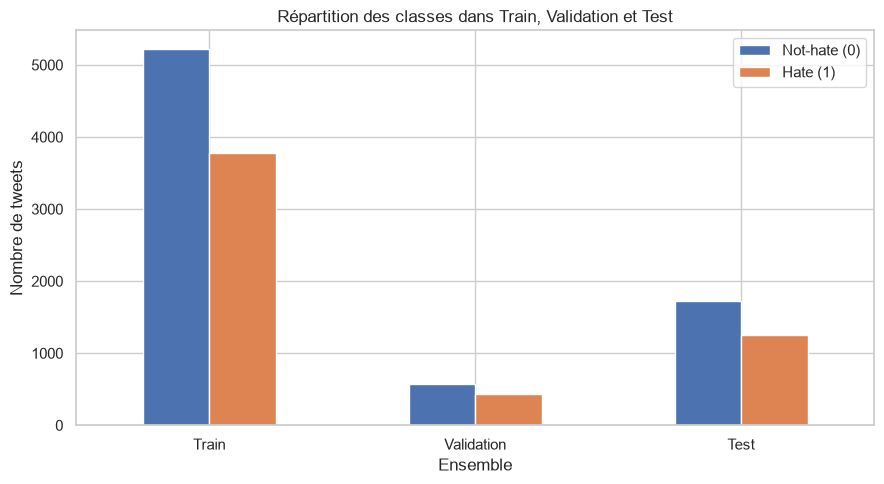

In [4]:
distribution = pd.DataFrame({
    name: frame["label"].value_counts().reindex([0, 1], fill_value=0)
    for name, frame in [("Train", train), ("Validation", val), ("Test", test)]
})
distribution.index = ["Not-hate (0)", "Hate (1)"]
display(distribution)
display((distribution.div(distribution.sum(axis=0), axis=1) * 100).round(2).add_suffix(" (%)"))

ax = distribution.T.plot(kind="bar", figsize=(9, 5))
ax.set_title("Répartition des classes dans Train, Validation et Test")
ax.set_xlabel("Ensemble")
ax.set_ylabel("Nombre de tweets")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## 5. Longueur des textes : nombre de mots et de caractères

Statistiques de longueur sur Train :


,word_count,char_count
count,9000.00,9000.00
mean,20.82,123.86
std,10.87,67.21
min,0.00,0.00
25%,13.00,73.00
50%,19.00,111.00
75%,27.00,153.00
max,63.00,304.00


Statistiques par classe :


,word_count,char_count
label,,
Hate,21.90,131.14
Not-hate,20.04,118.58


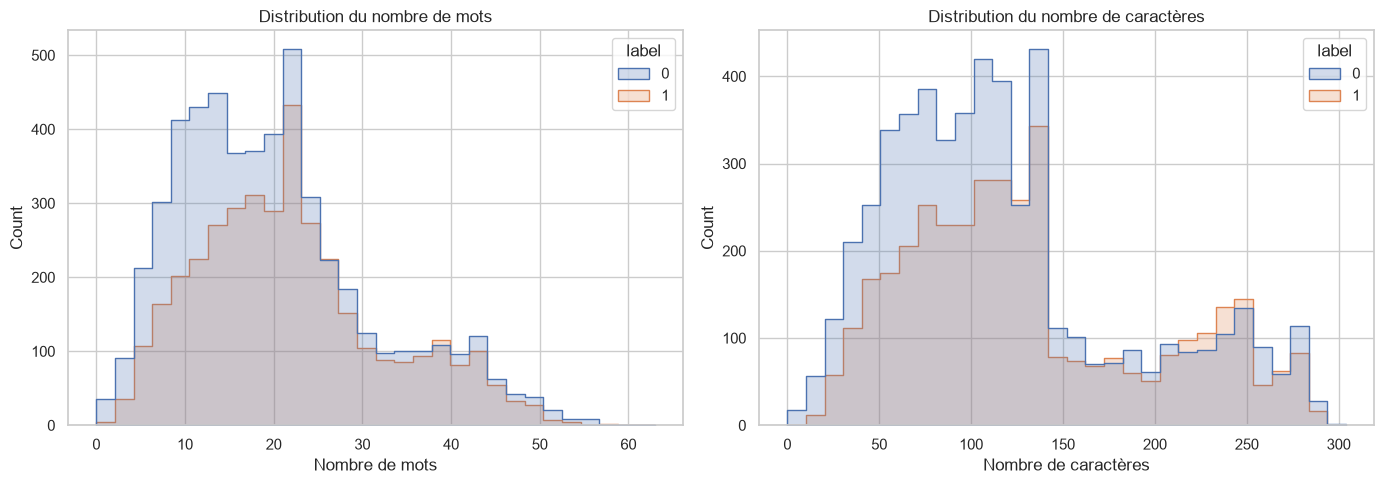

In [5]:
for frame in [train, val, test]:
    frame["word_count"] = frame["text"].str.split().str.len()
    frame["char_count"] = frame["text"].str.len()

print("Statistiques de longueur sur Train :")
display(train[["word_count", "char_count"]].describe().round(2))
print("Statistiques par classe :")
display(train.groupby(train["label"].map(LABEL_NAMES))[["word_count", "char_count"]].mean().round(2))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(data=train, x="word_count", hue="label", bins=30, element="step", stat="count", common_norm=False, ax=axes[0])
axes[0].set_title("Distribution du nombre de mots")
axes[0].set_xlabel("Nombre de mots")
sns.histplot(data=train, x="char_count", hue="label", bins=30, element="step", stat="count", common_norm=False, ax=axes[1])
axes[1].set_title("Distribution du nombre de caractères")
axes[1].set_xlabel("Nombre de caractères")
plt.tight_layout()
plt.show()

## 6. WordCloud : mots fréquents par classe (textes bruts)

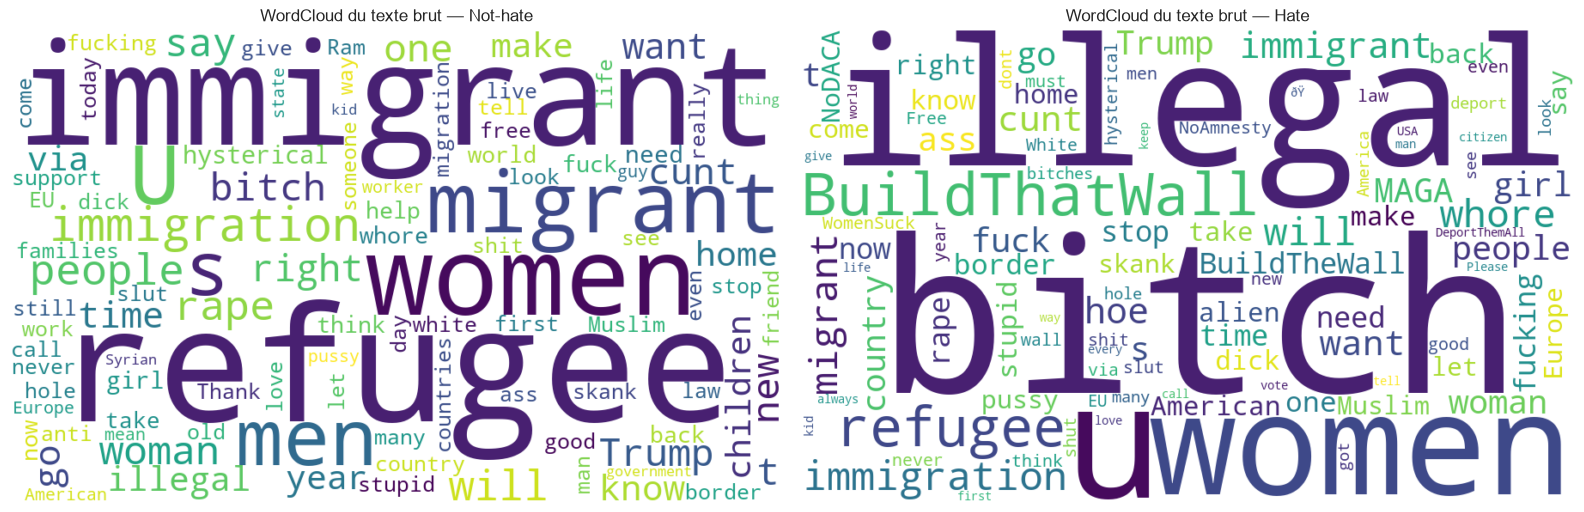

In [6]:
TECHNICAL_TOKENS = {"user", "http", "https", "co", "amp"}
RAW_WORDCLOUD_STOPS = set(STOPWORDS) | TECHNICAL_TOKENS

def show_wordclouds(frame, column, stop_words, title_prefix):
    fig, axes = plt.subplots(1, 2, figsize=(16, 7))
    for ax, label in zip(axes, [0, 1]):
        text_value = " ".join(frame.loc[frame["label"] == label, column].fillna("").astype(str))
        if not text_value.strip():
            ax.text(0.5, 0.5, "Aucun mot à afficher", ha="center", va="center")
        else:
            cloud = WordCloud(width=900, height=550, background_color="white",
                              max_words=100, stopwords=stop_words,
                              collocations=False, random_state=RANDOM_STATE).generate(text_value)
            ax.imshow(cloud, interpolation="bilinear")
        ax.axis("off")
        ax.set_title(f"{title_prefix} — {LABEL_NAMES[label]}")
    plt.tight_layout()
    plt.show()

show_wordclouds(train, "text", RAW_WORDCLOUD_STOPS, "WordCloud du texte brut")

# 2. Prétraitement du texte

## 7. Vérification des éléments présents dans les tweets

Cette étape mesure la présence des URLs, mentions, hashtags, négations, majuscules et entités HTML. Elle sert à justifier les choix de nettoyage à partir du contenu réel du dataset.

In [7]:
raw_text = train["text"].fillna("").astype(str)
content_stats = pd.DataFrame({
    "URL": raw_text.str.contains(r"https?://\S+|www\.\S+", regex=True, case=False),
    "Mention (@user)": raw_text.str.contains(r"@\w+", regex=True),
    "Hashtag": raw_text.str.contains(r"#\w+", regex=True),
    "Négation": raw_text.str.lower().str.contains(r"\b(?:no|not|never|nor|neither|nobody|none|nothing|nowhere)\b|n't\b", regex=True),
    "Mot en majuscules": raw_text.str.contains(r"\b[A-Z]{2,}\b", regex=True),
    "Entité HTML": raw_text.str.contains(r"&\w+;", regex=True),
})
content_percent = (content_stats.mean() * 100).rename("Pourcentage des tweets")
display(content_percent.to_frame().round(2))


,Pourcentage des tweets
URL,1.42
Mention (@user),38.86
Hashtag,25.81
Négation,28.19
Mot en majuscules,28.77
Entité HTML,3.07


## 8. Choix de nettoyage et justification

| Élément | Traitement appliqué | Justification |
|---|---|---|
| Minuscules | Conversion en minuscules | Uniformiser les formes d'un même mot. |
| URLs | Suppression complète | Le lien lui-même n'est pas un mot exploitable par TF-IDF. |
| Mentions `@user` | Suppression du nom mentionné | Éviter d'apprendre des identifiants de comptes. |
| Hashtags | Suppression de `#` et du mot du hashtag | Interprétation stricte de la consigne « supprimer les hashtags ». Cette suppression peut faire perdre du contexte ; cette limite est signalée. |
| Ponctuation, chiffres, emojis et caractères spéciaux | Suppression | Garder uniquement les mots alphabétiques anglais. |
| Stopwords anglais | Suppression | Réduire les mots très fréquents peu informatifs. |
| Négations | Conservation de `no`, `not`, `nor`, `never`, etc. ; développement des contractions négatives | Une négation peut inverser le sens d'un tweet et être importante pour la détection de haine. |
| Lemmatisation | Non appliquée | Elle est optionnelle dans le descriptif du projet. |

Les mêmes règles sont appliquées aux ensembles Train, Validation et Test. Les lignes ne sont jamais supprimées, même si un texte devient vide, afin de conserver l'alignement avec les labels.

## 9. Fonction de nettoyage — version corrigée

In [8]:
NEGATIONS = {
    "no", "not", "nor", "never", "neither", "nobody", "none",
    "nothing", "nowhere", "against"
}
STOP_WORDS = set(ENGLISH_STOP_WORDS) - NEGATIONS

# Lemmatisation facultative dans le PDF : non appliquée dans ce projet.
LEMMATIZE = False

# IMPORTANT : chaque expression régulière contient un seul antislash dans une chaîne raw.
URL_RE = re.compile(r"https?://\S+|www\.\S+", flags=re.IGNORECASE)
MENTION_RE = re.compile(r"@\w+", flags=re.IGNORECASE)
# Pas de lookbehind : permet aussi de supprimer des hashtags collés, ex. #A#B.
HASHTAG_RE = re.compile(r"#\w+", flags=re.IGNORECASE)
NON_LETTER_RE = re.compile(r"[^a-z\s]")
MULTISPACE_RE = re.compile(r"\s+")


def expand_negative_contractions(text):
    """Développe les contractions négatives afin de ne pas perdre NOT."""
    text = re.sub(r"\bcan't\b", "can not", text)
    text = re.sub(r"\bcannot\b", "can not", text)
    text = re.sub(r"\bwon't\b", "will not", text)
    text = re.sub(r"\bshan't\b", "shall not", text)
    text = re.sub(r"\bain't\b", "is not", text)
    return re.sub(r"\b([a-z]+)n't\b", r"\1 not", text)


def remove_other_contraction_suffixes(text):
    """Évite les fragments inutiles 's, 've, 're, 'll, 'd et 'm après nettoyage."""
    return re.sub(r"\b([a-z]+)'(?:s|ve|re|ll|d|m)\b", r"\1", text)


def clean_text(value):
    if pd.isna(value):
        return ""

    # 1. Décoder HTML, convertir en minuscules et uniformiser les apostrophes.
    text = html.unescape(str(value)).lower()
    text = text.replace("’", "'").replace("‘", "'").replace("`", "'")

    # 2. Supprimer les URLs, mentions et hashtags complets.
    text = URL_RE.sub(" ", text)
    text = MENTION_RE.sub(" ", text)
    text = HASHTAG_RE.sub(" ", text)

    # 3. Conserver les négations avant de retirer la ponctuation.
    text = expand_negative_contractions(text)
    text = remove_other_contraction_suffixes(text)

    # 4. Supprimer ponctuation, chiffres, emojis et caractères spéciaux.
    text = NON_LETTER_RE.sub(" ", text)
    tokens = MULTISPACE_RE.sub(" ", text).strip().split()

    # 5. Retirer les stopwords, sauf les négations protégées.
    # Les tokens d'une seule lettre sont éliminés (ex. fragments 's' ou 've').
    tokens = [word for word in tokens if word not in STOP_WORDS and len(word) > 1]

    # LEMMATIZE=False : aucune lemmatisation n'est appliquée.
    return " ".join(tokens)


# Vérification rapide des expressions régulières avant de traiter le dataset.
assert URL_RE.search("lien https://t.co/abc")
assert MENTION_RE.search("bonjour @user")
assert HASHTAG_RE.findall("#NoDACA#DeportThemAll") == ["#NoDACA", "#DeportThemAll"]
print("Expressions régulières vérifiées : URL, mention et hashtags (y compris collés).")


Expressions régulières vérifiées : URL, mention et hashtags (y compris collés).


## 10. Tests unitaires ciblés avant le nettoyage de tous les fichiers

In [9]:
test_cases = [
    ("@user They should NOT come here!! #BuildTheWall https://t.co/abc", "not come"),
    ("I don't like this. They aren't welcome!", "not like not welcome"),
    ("We can't accept this situation. #RefugeesNotWelcome", "not accept situation"),
    ("Visit www.example.com now @user", "visit"),
    ("#MAGA #NoDACA", ""),
    ("hello#TAG#SECOND @userx", "hello"),
    ("We've got no reason to stop", "got no reason stop"),
]

for original, expected in test_cases:
    result = clean_text(original)
    print("AVANT :", original)
    print("APRÈS :", repr(result))
    assert result == expected, f"Échec du test. Attendu={expected!r}, obtenu={result!r}"
    print("TEST : OK\n")

print("Tous les tests unitaires de nettoyage sont réussis.")


AVANT : @user They should NOT come here!! #BuildTheWall https://t.co/abc
APRÈS : 'not come'
TEST : OK

AVANT : I don't like this. They aren't welcome!
APRÈS : 'not like not welcome'
TEST : OK

AVANT : We can't accept this situation. #RefugeesNotWelcome
APRÈS : 'not accept situation'
TEST : OK

AVANT : Visit www.example.com now @user
APRÈS : 'visit'
TEST : OK

AVANT : #MAGA #NoDACA
APRÈS : ''
TEST : OK

AVANT : hello#TAG#SECOND @userx
APRÈS : 'hello'
TEST : OK

AVANT : We've got no reason to stop
APRÈS : 'got no reason stop'
TEST : OK

Tous les tests unitaires de nettoyage sont réussis.


## 11. Création de `text_clean` sur Train, Validation et Test

In [10]:
for frame in [train, val, test]:
    # Le nettoyage est recalculé depuis la colonne brute text.
    frame["text_clean"] = frame["text"].apply(clean_text)

print("Exemples Train :")
display(train[["text", "text_clean", "label"]].head(12))
print("Exemples contenant des mentions, hashtags ou liens dans le texte brut :")
mask = train["text"].str.contains(r"@\w+|#\w+|https?://|www\.", regex=True, na=False)
display(train.loc[mask, ["text", "text_clean"]].head(12))


Exemples Train :


,text,text_clean,label
0,@user nice new signage. Are you not concerned by Beatlemania -style hysterical crowds crongregating on you…,nice new signage not concerned beatlemania style hysterical crowds crongregating,0
1,A woman who you fucked multiple times saying yo dick small is a compliment you know u hit that spot 😎,woman fucked multiple times saying yo dick small compliment know hit spot,1
2,@user @user real talk do you have eyes or were they gouged out by a rapefugee?,real talk eyes gouged rapefugee,1
3,your girlfriend lookin at me like a groupie in this bitch!,girlfriend lookin like groupie bitch,1
4,Hysterical woman like @user,hysterical woman like,0
5,Me flirting- So tell me about your father...,flirting tell father,0
6,"The Philippine Catholic bishops' work for migrant workers should focus on families who are ""paying the great...",philippine catholic bishops work migrant workers focus families paying great,0
7,I AM NOT GOING AFTER YOUR EX BF YOU LIEING SACK OF SHIT ! I'm done with you dude that's why I dumped your ass cause your a lieing 😂😡 bitch,not going ex bf lieing sack shit dude dumped ass cause lieing bitch,1
8,When cuffin season is finally over,cuffin season finally,0
9,"Send home migrants not in need of protection, Peter Dutton tells UN, HEY DUTTON HOW ABOUT THE ONES THAT HAVE STAYED AND NOT LEFT THE COU...",send home migrants not need protection peter dutton tells hey dutton ones stayed not left country overstayers dont round,1


Exemples contenant des mentions, hashtags ou liens dans le texte brut :


,text,text_clean
0,@user nice new signage. Are you not concerned by Beatlemania -style hysterical crowds crongregating on you…,nice new signage not concerned beatlemania style hysterical crowds crongregating
2,@user @user real talk do you have eyes or were they gouged out by a rapefugee?,real talk eyes gouged rapefugee
4,Hysterical woman like @user,hysterical woman like
12,Should have let the Libyan Manchester bomber rot in his own country. How many more mass murderers did the Royal Navy import to Britain? ...,let libyan manchester bomber rot country mass murderers did royal navy import britain terrorists ngo rescue international waters
13,More migrants take sea route to #Spain than Italy this year: UN,migrants sea route italy year
15,"This account was temporarily inactive due to an irrational woman reporting us to Twitter. What a lack of judgement, shocking. #YesAllMen",account temporarily inactive irrational woman reporting twitter lack judgement shocking
16,RT @user @user I am flattered tbh. I got an orgasm just by thinking of it you really are good at this.,rt flattered tbh got orgasm just thinking really good
19,@user @user keep calling her a bitch and a whore dude real grown up.,calling bitch whore dude real grown
20,"Glad your having another nice vacation. How's the illegal border crossings, illegal oportunistic migrant entries, tax payer funded hotel...",glad having nice vacation illegal border crossings illegal oportunistic migrant entries tax payer funded hotel rooms strategic plan going
21,"@user Unchecked Population&amp;migration to cities is biggest evil for dirty India.Disincentive large families,such as withdrawl of sops",unchecked population migration cities biggest evil dirty india disincentive large families withdrawl sops


## 12. Vérifications automatiques strictes du nettoyage

In [11]:
FORBIDDEN_PATTERNS = {
    "URL": URL_RE,
    "mention @user": MENTION_RE,
    "hashtag (# + mot)": HASHTAG_RE,
    "ponctuation / chiffre / caractère spécial": NON_LETTER_RE,
}

for split_name, frame in [("Train", train), ("Validation", val), ("Test", test)]:
    cleaned = frame["text_clean"].fillna("").astype(str)
    print(f"\n=== {split_name} ===")
    print("Nombre de lignes :", len(frame))
    print("Valeurs manquantes text_clean :", frame["text_clean"].isna().sum())
    print("Textes nettoyés vides :", int((cleaned.str.strip() == "").sum()))

    for description, pattern in FORBIDDEN_PATTERNS.items():
        count = int(cleaned.apply(lambda value: bool(pattern.search(value))).sum())
        print(f"{description} résiduel(s) : {count}")
        assert count == 0, f"{description} encore présent dans {split_name}"

    assert cleaned.str.fullmatch(r"[a-z ]*").all(), f"Caractères invalides dans {split_name}"
    assert cleaned.eq(cleaned.str.lower()).all(), f"Majuscules restantes dans {split_name}"
    for value in cleaned:
        tokens = value.split()
        residual_stopwords = [word for word in tokens if word in STOP_WORDS]
        assert not residual_stopwords, f"Stopwords résiduels dans {split_name}: {residual_stopwords[:5]}"
        assert all(len(word) > 1 for word in tokens), f"Fragment d'un caractère dans {split_name}: {value!r}"

    assert len(frame) == len(cleaned), f"Des lignes ont été perdues dans {split_name}"

print("\nVALIDATION GLOBALE : tous les tests sont réussis sur Train, Validation et Test.")



=== Train ===
Nombre de lignes : 9000
Valeurs manquantes text_clean : 0
Textes nettoyés vides : 58
URL résiduel(s) : 0
mention @user résiduel(s) : 0
hashtag (# + mot) résiduel(s) : 0
ponctuation / chiffre / caractère spécial résiduel(s) : 0

=== Validation ===
Nombre de lignes : 1000
Valeurs manquantes text_clean : 0
Textes nettoyés vides : 6
URL résiduel(s) : 0
mention @user résiduel(s) : 0
hashtag (# + mot) résiduel(s) : 0
ponctuation / chiffre / caractère spécial résiduel(s) : 0

=== Test ===
Nombre de lignes : 2970
Valeurs manquantes text_clean : 0
Textes nettoyés vides : 7
URL résiduel(s) : 0
mention @user résiduel(s) : 0
hashtag (# + mot) résiduel(s) : 0
ponctuation / chiffre / caractère spécial résiduel(s) : 0

VALIDATION GLOBALE : tous les tests sont réussis sur Train, Validation et Test.


## 13. Visualisation après nettoyage

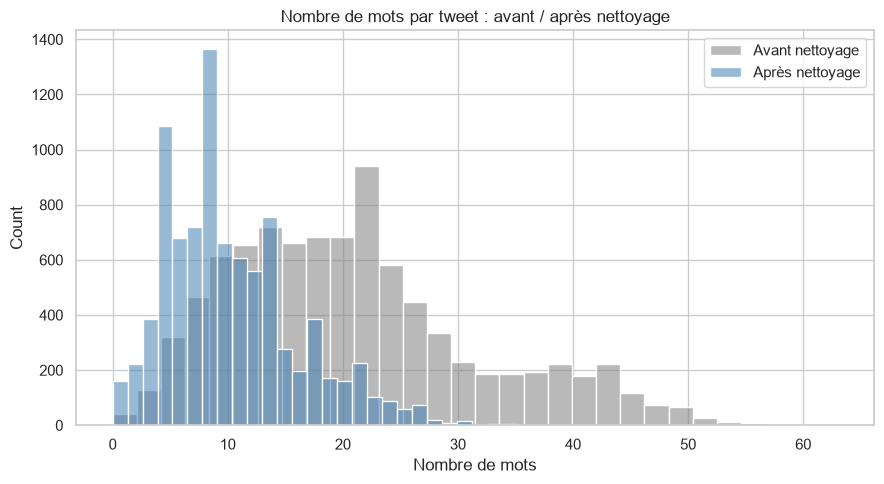

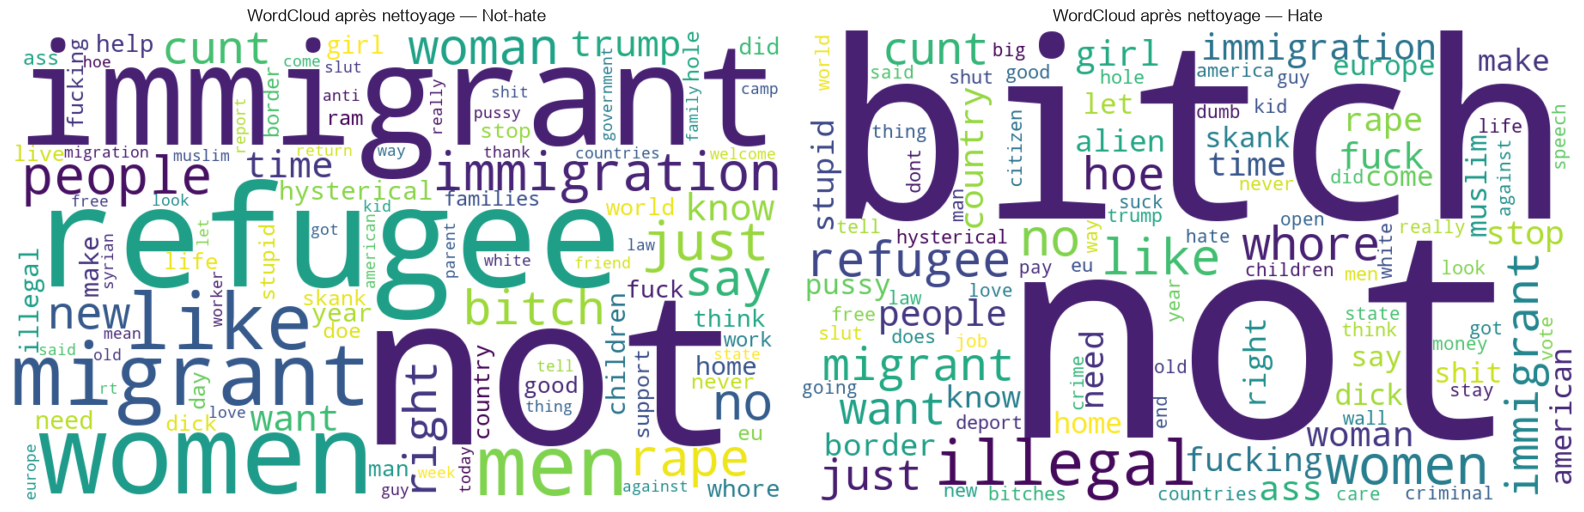

In [12]:
train["clean_word_count"] = train["text_clean"].str.split().str.len()
fig, ax = plt.subplots(figsize=(9, 5))
sns.histplot(train["word_count"], bins=30, color="gray", alpha=0.55, label="Avant nettoyage", ax=ax)
sns.histplot(train["clean_word_count"], bins=30, color="steelblue", alpha=0.55, label="Après nettoyage", ax=ax)
ax.set_title("Nombre de mots par tweet : avant / après nettoyage")
ax.set_xlabel("Nombre de mots")
ax.legend()
plt.tight_layout()
plt.show()

show_wordclouds(train, "text_clean", set(), "WordCloud après nettoyage")

## 14. Sauvegarde des fichiers nettoyés

Les fichiers exportés contiennent **uniquement** `text_clean` et `label`. La colonne brute `text` reste disponible dans le notebook pour l'EAD, mais elle n'est pas exportée. Ainsi, les anciennes mentions comme `@user` ne réapparaissent pas dans les CSV remis.

In [13]:
OUTPUT_DIR = Path("outputs_tweeteval_hate")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

export_paths = {}
for split_name, frame in [("train", train), ("val", val), ("test", test)]:
    output_path = OUTPUT_DIR / f"{split_name}_clean.csv"
    # Export strict : seulement le texte nettoyé et le label.
    frame[["text_clean", "label"]].to_csv(output_path, index=False, encoding="utf-8")

    # Relecture du fichier pour vérifier le résultat réellement écrit.
    exported = pd.read_csv(output_path, keep_default_na=False)
    assert list(exported.columns) == ["text_clean", "label"], \
        f"Colonnes inattendues dans {output_path.name}: {list(exported.columns)}"
    assert len(exported) == len(frame), f"Nombre de lignes modifié dans {output_path.name}"
    assert not exported["text_clean"].astype(str).str.contains(r"@|#|https?://|www\.", regex=True, case=False).any(), \
        f"Mention, hashtag ou URL restant dans {output_path.name}"
    assert exported["text_clean"].astype(str).str.fullmatch(r"[a-z ]*").all(), \
        f"Caractère interdit restant dans {output_path.name}"

    export_paths[split_name] = output_path
    print(f"{output_path.resolve()} — {len(exported)} lignes — colonnes : {list(exported.columns)} — vérification OK")

print("Les trois CSV simplifiés ont été enregistrés dans :", OUTPUT_DIR.resolve())

C:\Users\ouesl\Downloads\tweeteval-main2\tweeteval-main\outputs_tweeteval_hate\train_clean.csv — 9000 lignes — colonnes : ['text_clean', 'label'] — vérification OK
C:\Users\ouesl\Downloads\tweeteval-main2\tweeteval-main\outputs_tweeteval_hate\val_clean.csv — 1000 lignes — colonnes : ['text_clean', 'label'] — vérification OK
C:\Users\ouesl\Downloads\tweeteval-main2\tweeteval-main\outputs_tweeteval_hate\test_clean.csv — 2970 lignes — colonnes : ['text_clean', 'label'] — vérification OK
Les trois CSV simplifiés ont été enregistrés dans : C:\Users\ouesl\Downloads\tweeteval-main2\tweeteval-main\outputs_tweeteval_hate


# 3. Vectorisation

## 15. Vectorisation TF-IDF

Le vectoriseur est ajusté uniquement sur Train. L'ensemble Validation sert à comparer les modèles. L'ensemble Test reste réservé à l'évaluation finale.

In [14]:
tfidf = TfidfVectorizer(
    lowercase=False,           # text_clean est déjà en minuscules
    ngram_range=(1, 2),        # unigrammes et bigrammes
    min_df=2,
    max_features=50000,
    sublinear_tf=True
)

X_train = tfidf.fit_transform(train["text_clean"])
X_val = tfidf.transform(val["text_clean"])
y_train = train["label"].to_numpy()
y_val = val["label"].to_numpy()

print("Matrice Train :", X_train.shape)
print("Matrice Validation :", X_val.shape)
print("Nombre de caractéristiques TF-IDF :", len(tfidf.get_feature_names_out()))

Matrice Train : (9000, 13139)
Matrice Validation : (1000, 13139)
Nombre de caractéristiques TF-IDF : 13139


# 4. Application de cinq algorithmes de Machine Learning

## 16. Entraînement et évaluation sur Validation

Les cinq modèles choisis sont : Régression Logistique, SVM linéaire, Random Forest, Naive Bayes et KNN. Les métriques sont calculées avec une moyenne macro pour tenir compte des deux classes.

In [15]:
models = {
    "Régression Logistique": LogisticRegression(max_iter=2000, class_weight="balanced", random_state=RANDOM_STATE),
    "SVM (LinearSVC)": LinearSVC(class_weight="balanced", random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(n_estimators=150, min_samples_leaf=2,
                                             class_weight="balanced_subsample",
                                             random_state=RANDOM_STATE, n_jobs=-1),
    "Naive Bayes": MultinomialNB(alpha=0.5),
    "KNN": KNeighborsClassifier(n_neighbors=5, metric="cosine", algorithm="brute", n_jobs=-1),
}

results = []
validation_predictions = {}

for model_name, model in models.items():
    print("Entraînement :", model_name)
    model.fit(X_train, y_train)
    pred = model.predict(X_val)
    validation_predictions[model_name] = pred
    results.append({
        "Modèle": model_name,
        "Accuracy": accuracy_score(y_val, pred),
        "Precision macro": precision_score(y_val, pred, average="macro", zero_division=0),
        "Recall macro": recall_score(y_val, pred, average="macro", zero_division=0),
        "F1-score macro": f1_score(y_val, pred, average="macro", zero_division=0),
    })

results_df = pd.DataFrame(results).sort_values("F1-score macro", ascending=False).reset_index(drop=True)
display(results_df.round(4))

Entraînement : Régression Logistique
Entraînement : SVM (LinearSVC)
Entraînement : Random Forest
Entraînement : Naive Bayes
Entraînement : KNN


,Modèle,Accuracy,Precision macro,Recall macro,F1-score macro
0,Naive Bayes,0.703,0.6963,0.6919,0.6934
1,Random Forest,0.684,0.6867,0.6905,0.6830
2,SVM (LinearSVC),0.683,0.6780,0.6804,0.6786
3,Régression Logistique,0.667,0.6679,0.6715,0.6655
4,KNN,0.655,0.6490,0.6506,0.6495


## 17. Rapports de classification et matrices de confusion

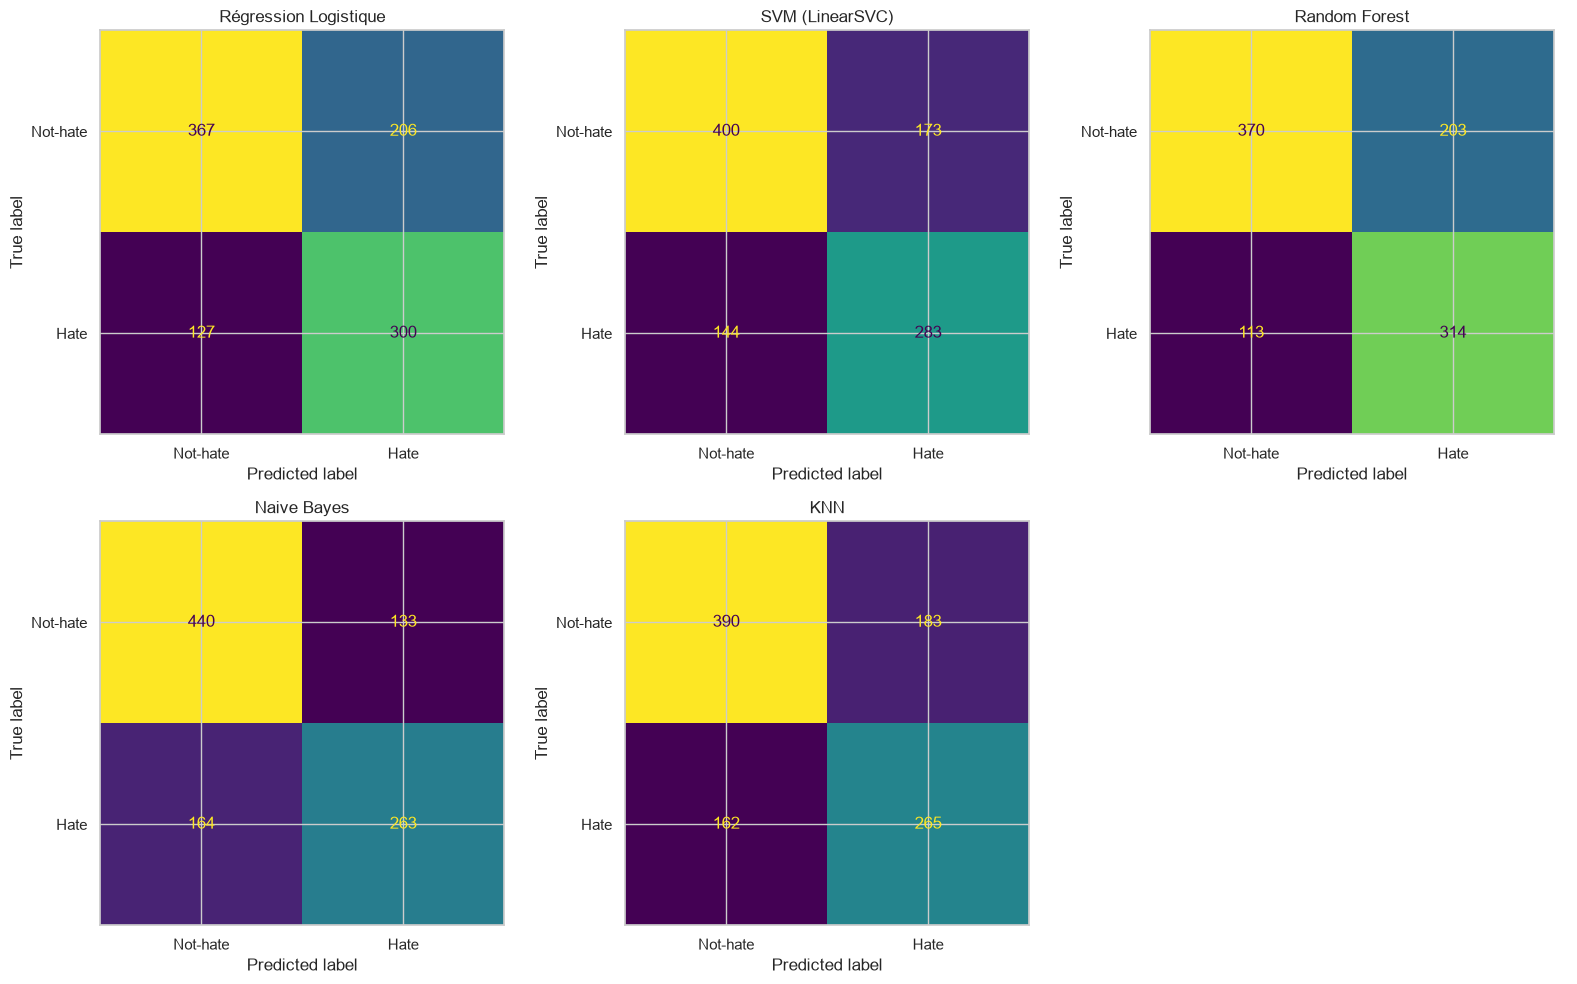


=== Régression Logistique ===
              precision    recall  f1-score   support

    Not-hate       0.74      0.64      0.69       573
        Hate       0.59      0.70      0.64       427

    accuracy                           0.67      1000
   macro avg       0.67      0.67      0.67      1000
weighted avg       0.68      0.67      0.67      1000


=== SVM (LinearSVC) ===
              precision    recall  f1-score   support

    Not-hate       0.74      0.70      0.72       573
        Hate       0.62      0.66      0.64       427

    accuracy                           0.68      1000
   macro avg       0.68      0.68      0.68      1000
weighted avg       0.69      0.68      0.68      1000


=== Random Forest ===
              precision    recall  f1-score   support

    Not-hate       0.77      0.65      0.70       573
        Hate       0.61      0.74      0.67       427

    accuracy                           0.68      1000
   macro avg       0.69      0.69      0.68      

In [16]:
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
axes = axes.ravel()
for ax, (model_name, predictions) in zip(axes, validation_predictions.items()):
    cm = confusion_matrix(y_val, predictions, labels=[0, 1])
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Not-hate", "Hate"])
    disp.plot(ax=ax, colorbar=False, values_format="d")
    ax.set_title(model_name)
for ax in axes[len(validation_predictions):]:
    ax.axis("off")
plt.tight_layout()
plt.show()

for model_name, predictions in validation_predictions.items():
    print("\n===", model_name, "===")
    print(classification_report(y_val, predictions, target_names=["Not-hate", "Hate"], zero_division=0))

# 5. Comparaison et sélection du meilleur modèle

## 18. Sélection sur Validation

Le meilleur modèle est sélectionné selon le F1-score macro sur Validation. Le Test n'intervient pas dans cette sélection.

In [17]:
best_model_name = results_df.loc[0, "Modèle"]
best_validation_f1 = float(results_df.loc[0, "F1-score macro"])
print("Meilleur modèle sur Validation :", best_model_name)
print(f"F1-score macro Validation : {best_validation_f1:.4f}")

Meilleur modèle sur Validation : Naive Bayes
F1-score macro Validation : 0.6934


# 6. Test final et sauvegarde

## 19. Réentraînement du meilleur modèle sur Train + Validation, puis évaluation unique sur Test

Après la sélection, le vectoriseur et le meilleur classifieur sont réajustés sur Train + Validation. Le Test est utilisé une seule fois pour estimer la performance finale.

Modèle final : Naive Bayes
              precision    recall  f1-score   support

    Not-hate       0.74      0.42      0.54      1718
        Hate       0.50      0.80      0.62      1252

    accuracy                           0.58      2970
   macro avg       0.62      0.61      0.58      2970
weighted avg       0.64      0.58      0.57      2970

Accuracy Test : 0.5811
Precision macro Test : 0.6212
Recall macro Test : 0.6102
F1-score macro Test : 0.5778


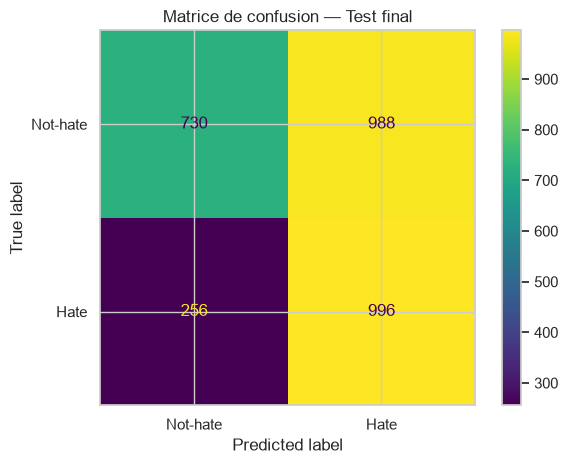

In [18]:
from sklearn.pipeline import Pipeline

train_val_text = pd.concat([train["text_clean"], val["text_clean"]], ignore_index=True)
y_train_val = np.concatenate([train["label"].to_numpy(), val["label"].to_numpy()])

final_vectorizer = TfidfVectorizer(
    lowercase=False,
    ngram_range=(1, 2),
    min_df=2,
    max_features=50000,
    sublinear_tf=True
)
X_train_val = final_vectorizer.fit_transform(train_val_text)
X_test = final_vectorizer.transform(test["text_clean"])

final_model = clone(models[best_model_name])
final_model.fit(X_train_val, y_train_val)
y_test = test["label"].to_numpy()
test_predictions = final_model.predict(X_test)

print("Modèle final :", best_model_name)
print(classification_report(y_test, test_predictions,
                            target_names=["Not-hate", "Hate"], zero_division=0))
print("Accuracy Test :", round(accuracy_score(y_test, test_predictions), 4))
print("Precision macro Test :", round(precision_score(y_test, test_predictions, average="macro", zero_division=0), 4))
print("Recall macro Test :", round(recall_score(y_test, test_predictions, average="macro", zero_division=0), 4))
print("F1-score macro Test :", round(f1_score(y_test, test_predictions, average="macro", zero_division=0), 4))

ConfusionMatrixDisplay.from_predictions(y_test, test_predictions,
                                        labels=[0, 1], display_labels=["Not-hate", "Hate"],
                                        values_format="d")
plt.title("Matrice de confusion — Test final")
plt.tight_layout()
plt.show()

In [19]:
final_pipeline = Pipeline([
    ("tfidf", final_vectorizer),
    ("classifier", final_model)
])
model_path = OUTPUT_DIR / "meilleur_modele_tweeteval_hate.joblib"
joblib.dump(final_pipeline, model_path)
print("Modèle final sauvegardé dans :", model_path.resolve())

Modèle final sauvegardé dans : C:\Users\ouesl\Downloads\tweeteval-main2\tweeteval-main\outputs_tweeteval_hate\meilleur_modele_tweeteval_hate.joblib


## 20. Bilan final

Le notebook a réalisé l'EAD, le nettoyage, la vectorisation TF-IDF, l'entraînement de cinq algorithmes, leur comparaison sur Validation, puis le test final du meilleur modèle et sa sauvegarde. Les trois CSV nettoyés dans `outputs_tweeteval_hate/` contiennent **uniquement** les colonnes `text_clean` et `label`.

**À compléter avant la remise :** les noms des membres du groupe dans l'en-tête et, dans votre présentation, l'interprétation des résultats réels obtenus après exécution.